# Trabajo Práctico: Predicción de lluvia en Australia
**Aprendizaje Automático 1 - Tecnicatura en Inteligencia Artificial (FCEIA)**

El objetivo es predecir, a las 23:59 de cada día, si al día siguiente va a llover (`RainTomorrow`). Es un problema de clasificación binaria.

In [1]:
# librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

SEED = 42  # semilla para que los resultados sean reproducibles

## 1. Análisis descriptivo

In [2]:
# se carga el dataset y se pasa la fecha a datetime
df = pd.read_csv("weatherAUS_2026C2.csv")
df["Date"] = pd.to_datetime(df["Date"])
print(df.shape)
df.head()

(145412, 25)


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


El archivo trae dos columnas que no son variables climáticas de entrada:
- `Unnamed: 0` no tiene información.
- `RainfallTomorrow` son los milímetros que llueven **mañana**. `RainTomorrow` es justamente "mañana llovió más de 1 mm", así que esta columna contiene la respuesta (data leakage). Si se usara como entrada, el modelo daría métricas casi perfectas pero inútiles, porque a las 23:59 de hoy ese dato no existe. Se elimina.

In [3]:
# se saca el índice sobrante y la columna que filtra el target
df = df.drop(columns=["Unnamed: 0", "RainfallTomorrow"])
print(df.shape)

(145412, 23)


In [4]:
# tipos de dato y cantidad de no nulos por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145412 non-null  datetime64[us]
 1   Location       145412 non-null  str           
 2   MinTemp        143928 non-null  float64       
 3   MaxTemp        144159 non-null  float64       
 4   Rainfall       142152 non-null  float64       
 5   Evaporation    82658 non-null   float64       
 6   Sunshine       75616 non-null   float64       
 7   WindGustDir    135096 non-null  str           
 8   WindGustSpeed  135159 non-null  float64       
 9   WindDir9am     134850 non-null  str           
 10  WindDir3pm     141186 non-null  str           
 11  WindSpeed9am   143645 non-null  float64       
 12  WindSpeed3pm   142351 non-null  float64       
 13  Humidity9am    142759 non-null  float64       
 14  Humidity3pm    140907 non-null  float64       
 15  Pressure9am

In [5]:
# resumen estadístico de las variables numéricas
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,145412,2013-04-04 08:55:50.149919,2007-11-01 00:00:00,2011-01-10 00:00:00,2013-06-02 00:00:00,2015-06-14 00:00:00,2017-06-24 00:00:00,NaN
MinTemp,143928.0,12.196528,-9.7,7.6,12.0,16.9,34.1,6.417956
MaxTemp,144159.0,23.223064,-5.1,17.9,22.6,28.2,49.1,7.135927
Rainfall,142152.0,2.361516,0.0,0.0,0.0,0.8,371.0,8.479338
Evaporation,82658.0,5.468616,0.0,2.6,4.8,7.4,145.0,4.193871
Sunshine,75616.0,7.611241,0.0,4.8,8.4,10.6,14.5,3.785612
WindGustSpeed,135159.0,40.036668,6.0,31.0,38.0,48.0,135.0,13.648259
WindSpeed9am,143645.0,14.067277,0.0,7.0,13.0,19.0,130.0,8.936768
WindSpeed3pm,142351.0,18.661899,0.0,12.0,18.0,24.0,86.0,8.865457
Humidity9am,142759.0,68.861521,0.0,57.0,69.9,83.1,100.0,19.062866


In [6]:
# resumen de las variables categóricas y rango de fechas
print(df.select_dtypes("object").describe().T)
print("\nPeríodo:", df["Date"].min().date(), "a", df["Date"].max().date())
print("Cantidad de ciudades:", df["Location"].nunique())

               count unique       top    freq
Location      145412     49  Canberra    3435
WindGustDir   135096     16         W    9910
WindDir9am    134850     16         N   11754
WindDir3pm    141186     16        SE   10837
RainToday     142152      2        No  110276
RainTomorrow  142153      2        No  110281

Período: 2007-11-01 a 2017-06-24
Cantidad de ciudades: 49


C:\Users\reneb\AppData\Local\Temp\ipykernel_21104\3479520882.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes("object").describe().T)


### ¿Qué es cada variable?

| Variable | Tipo | Descripción |
|---|---|---|
| Date | fecha | día de la observación |
| Location | categórica | ciudad/estación donde se midió |
| MinTemp, MaxTemp | numérica (°C) | temperatura mínima y máxima del día |
| Rainfall | numérica (mm) | lluvia caída en las 24 hs previas a las 9am |
| Evaporation | numérica (mm) | evaporación (tanque clase A) en las 24 hs previas a las 9am |
| Sunshine | numérica (hs) | horas de sol brillante durante el día |
| WindGustDir | categórica | dirección de la ráfaga de viento más fuerte del día |
| WindGustSpeed | numérica (km/h) | velocidad de esa ráfaga |
| WindDir9am, WindDir3pm | categórica | dirección del viento a las 9am y 3pm |
| WindSpeed9am, WindSpeed3pm | numérica (km/h) | velocidad media del viento (10 min previos) a las 9am y 3pm |
| Humidity9am, Humidity3pm | numérica (%) | humedad relativa a las 9am y 3pm |
| Pressure9am, Pressure3pm | numérica (hPa) | presión atmosférica a nivel del mar a las 9am y 3pm |
| Cloud9am, Cloud3pm | numérica (octas, 0 a 8) | fracción del cielo cubierta por nubes |
| Temp9am, Temp3pm | numérica (°C) | temperatura a las 9am y 3pm |
| RainToday | categórica (Yes/No) | si hoy llovió más de 1 mm |
| RainTomorrow | categórica (Yes/No) | **variable objetivo**: si mañana llueve más de 1 mm |

Como la predicción se hace a las 23:59, todas las mediciones del día ya están disponibles y se pueden usar como variables de entrada.

### Datos faltantes

In [7]:
# cantidad de datos faltantes de la variable objetivo
print("Faltantes en RainTomorrow:", df["RainTomorrow"].isna().sum())

Faltantes en RainTomorrow: 3259


Las filas sin `RainTomorrow` no sirven para entrenar ni para evaluar (no tenemos la respuesta correcta), y imputar el target inventaría datos. Las eliminamos.

In [8]:
# se eliminan las filas sin target y se pasa a 0/1
df = df.dropna(subset=["RainTomorrow"]).reset_index(drop=True)
df["RainTomorrow"] = df["RainTomorrow"].map({"No": 0, "Yes": 1})
print(df.shape)

(142153, 23)


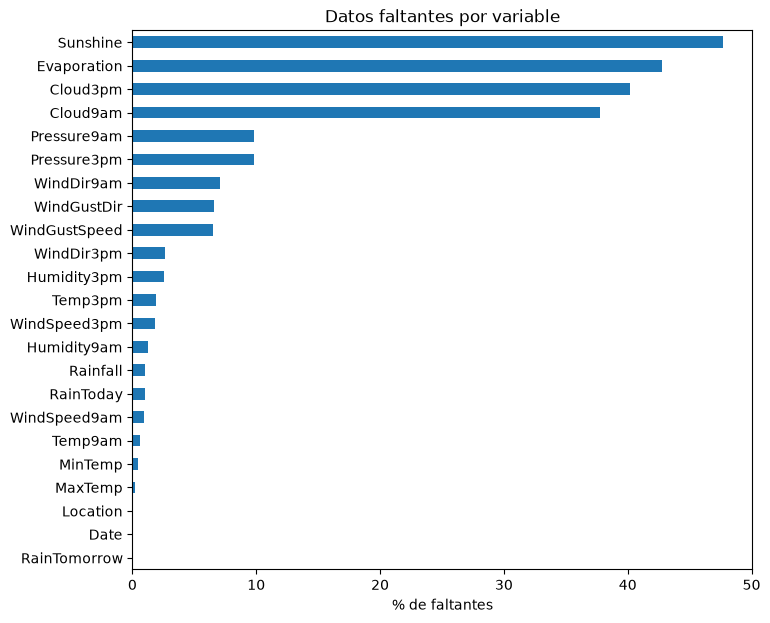

Sunshine         47.7
Evaporation      42.8
Cloud3pm         40.2
Cloud9am         37.7
Pressure9am       9.9
Pressure3pm       9.8
WindDir9am        7.0
WindGustDir       6.6
WindGustSpeed     6.5
WindDir3pm        2.7
Humidity3pm       2.5
Temp3pm           1.9
WindSpeed3pm      1.8
Humidity9am       1.2
Rainfall          1.0
RainToday         1.0
WindSpeed9am      0.9
Temp9am           0.6
MinTemp           0.4
MaxTemp           0.2
Location          0.0
Date              0.0
RainTomorrow      0.0
dtype: float64


In [9]:
# porcentaje de datos faltantes por columna
faltantes = (df.isna().mean() * 100).sort_values(ascending=False)
faltantes.plot.barh(figsize=(8, 7))
plt.xlabel("% de faltantes")
plt.gca().invert_yaxis()
plt.title("Datos faltantes por variable")
plt.show()
print(faltantes.round(1))

In [10]:
# porcentaje de datos faltantes de las variables con más NaN, según la ciudad (algunas estaciones no miden ciertas variables)
col_chequeo = faltantes.index[0]
por_ciudad = df.groupby("Location")[col_chequeo].apply(lambda s: s.isna().mean() * 100).sort_values(ascending=False)
print("% de faltantes de", col_chequeo, "por ciudad (top 10):")
print(por_ciudad.head(10).round(1))

% de faltantes de Sunshine por ciudad (top 10):
Location
Albury           100.0
GoldCoast        100.0
BadgerysCreek    100.0
Bendigo          100.0
Ballarat         100.0
Katherine        100.0
Wollongong       100.0
Walpole          100.0
Uluru            100.0
Richmond         100.0
Name: Sunshine, dtype: float64


**Decisión sobre faltantes**

- Las variables con más del 40% de faltantes se eliminan: imputar casi la mitad de una columna con un valor constante agregaría más ruido que información. Además, los faltantes no parecen aleatorios: hay ciudades que directamente no miden algunas variables (ver tabla anterior).
- Con el umbral de 40% se eliminan `Sunshine`, `Evaporation` y `Cloud3pm`. `Cloud9am` queda apenas por debajo (cerca de 38%) y se conserva; es una decisión de corte, y `Cloud9am` sigue aportando información sobre nubosidad.
- El resto se imputa con estadísticos calculados **solo sobre el conjunto de entrenamiento** (para no filtrar información de validación/test): mediana para las numéricas y moda para las categóricas.
- La imputación se hace después de separar train/val/test.

In [11]:
# se define el umbral de faltantes y qué columnas se eliminan
UMBRAL_FALTANTES = 40
cols_a_eliminar = faltantes[faltantes > UMBRAL_FALTANTES].index.tolist()
print("Columnas a eliminar:", cols_a_eliminar)

Columnas a eliminar: ['Sunshine', 'Evaporation', 'Cloud3pm']


### Visualización de datos

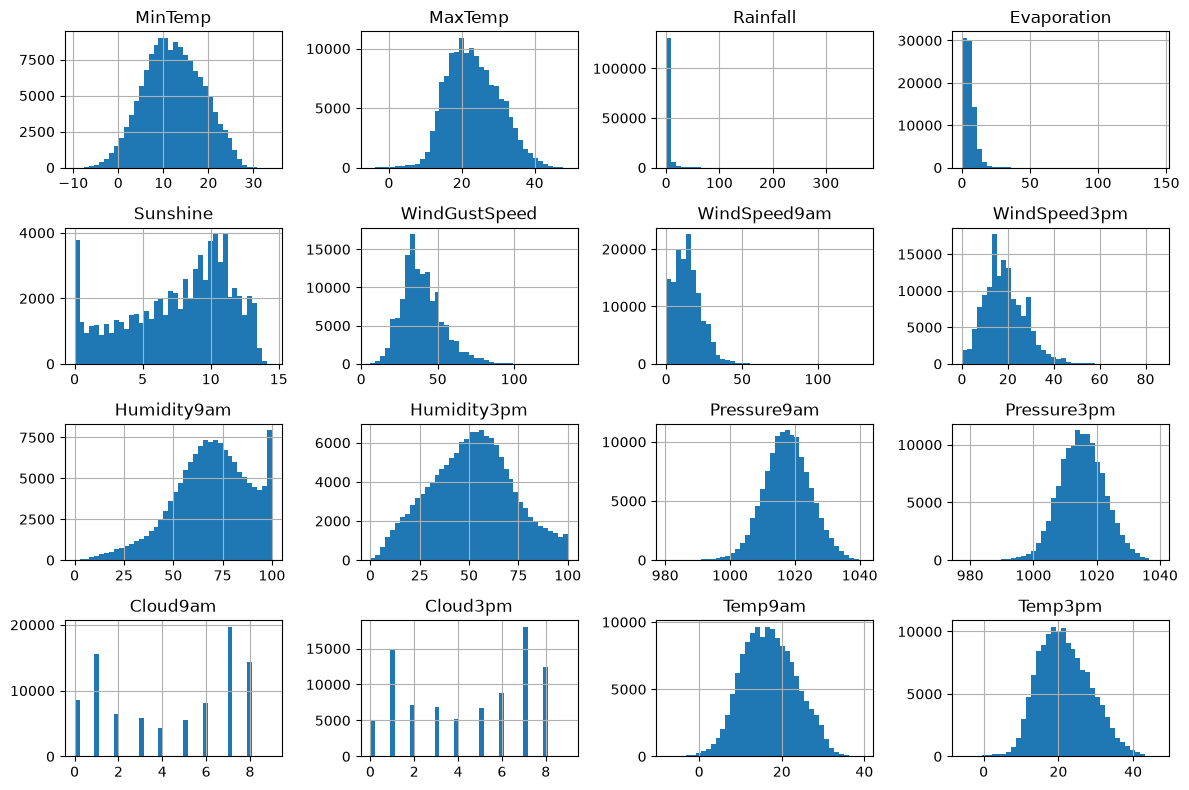

In [12]:
# histogramas de las variables numéricas
cols_numericas_eda = df.select_dtypes("number").columns.drop("RainTomorrow")
df[cols_numericas_eda].hist(bins=40, figsize=(12, 8))
plt.tight_layout()
plt.show()

Se ve que `Rainfall` y `Evaporation` tienen una distribución muy asimétrica a la derecha. Las temperaturas y la presión son bastante simétricas, y las humedades tienen forma más irregular. `Cloud` toma valores enteros de 0 a 8.

C:\Users\reneb\AppData\Local\Temp\ipykernel_21104\1497795748.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No", "Sí"])
C:\Users\reneb\AppData\Local\Temp\ipykernel_21104\1497795748.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No", "Sí"])
C:\Users\reneb\AppData\Local\Temp\ipykernel_21104\1497795748.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No", "Sí"])
C:\Users\reneb\AppData\Local\Temp\ipykernel_21104\1497795748.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwi

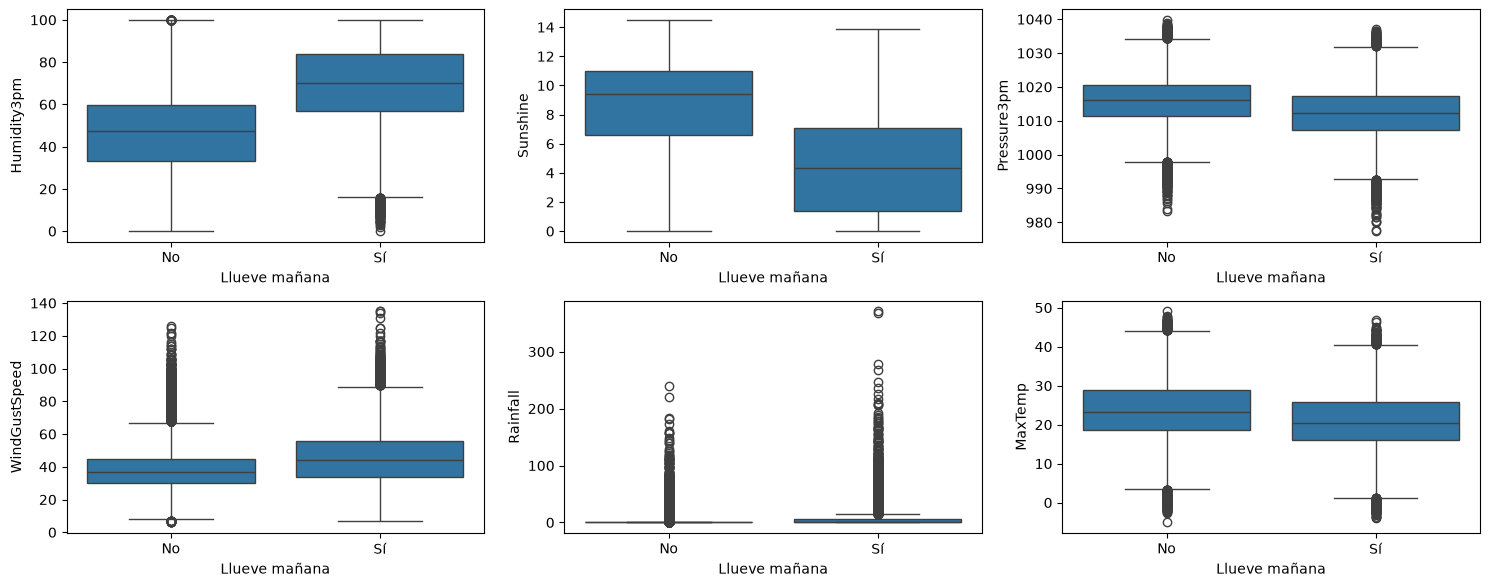

In [13]:
# boxplots de algunas variables según si llueve o no mañana
vars_box = ["Humidity3pm", "Sunshine", "Pressure3pm", "WindGustSpeed", "Rainfall", "MaxTemp"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, v in zip(axes.ravel(), vars_box):
    sns.boxplot(data=df, x="RainTomorrow", y=v, ax=ax)
    ax.set_xticklabels(["No", "Sí"])
    ax.set_xlabel("Llueve mañana")
plt.tight_layout()
plt.show()

Los días previos a una lluvia tienen mayor humedad a las 3pm, menos horas de sol, presión algo más baja y ráfagas más fuertes. `Rainfall` muestra muchos outliers, pero son valores reales (días de tormenta), por eso no los eliminamos.

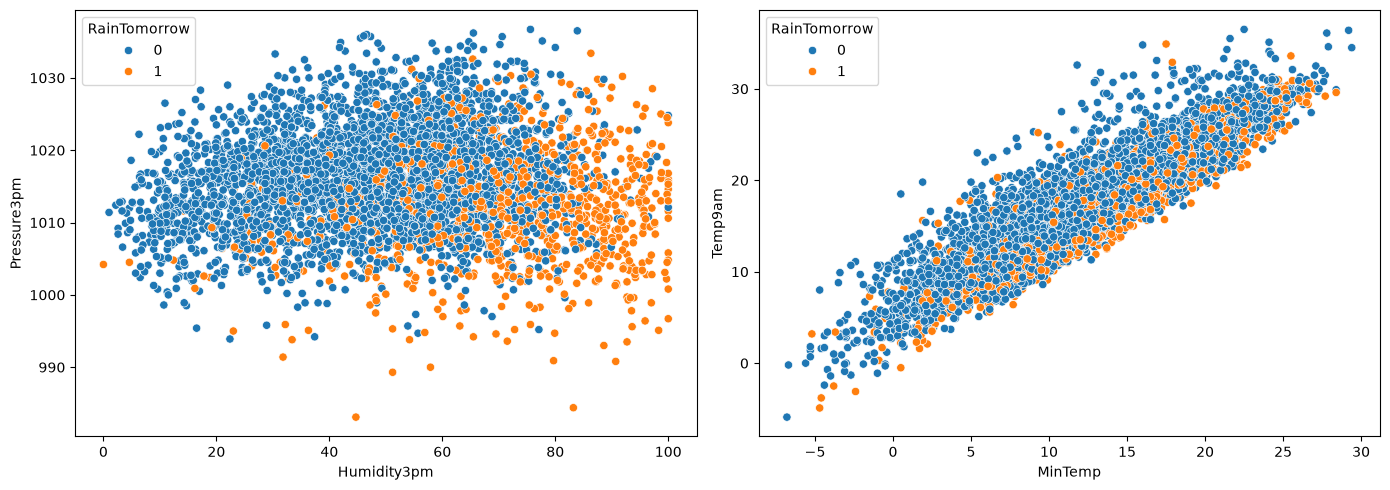

In [14]:
# scatterplots entre variables, usando una muestra para que se vea mejor
muestra = df.sample(5000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=muestra, x="Humidity3pm", y="Pressure3pm", hue="RainTomorrow", ax=axes[0])
sns.scatterplot(data=muestra, x="MinTemp", y="Temp9am", hue="RainTomorrow", ax=axes[1])
plt.tight_layout()
plt.show()

En el primer gráfico los días de lluvia se concentran con humedad alta y presión baja, aunque hay bastante solapamiento entre clases (el problema no es separable con una recta perfecta). El segundo muestra que `MinTemp` y `Temp9am` están muy relacionadas, algo que vamos a confirmar con la matriz de correlación.

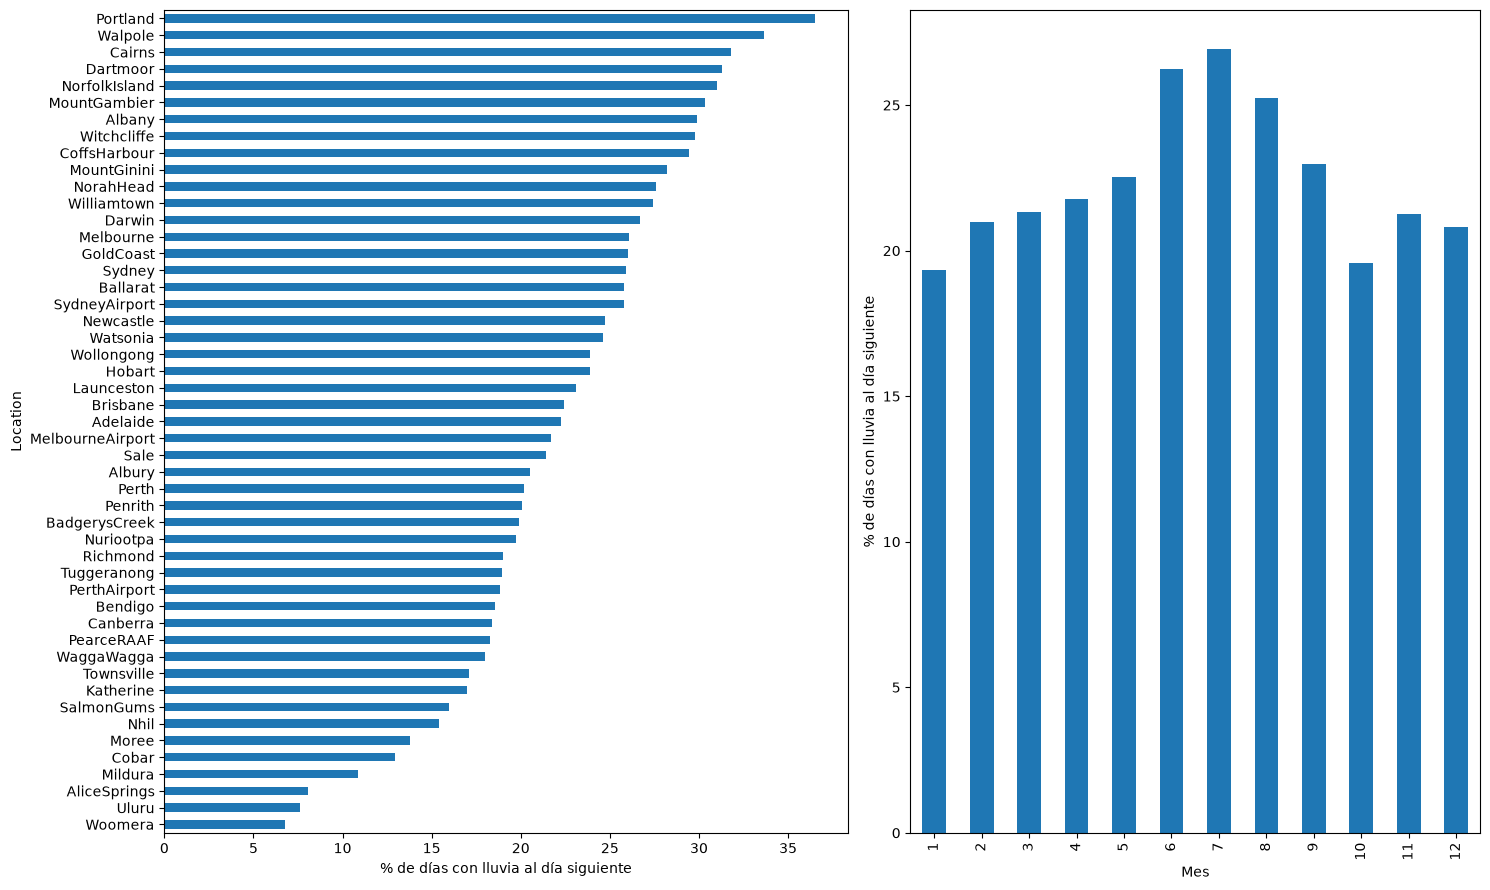

In [15]:
# proporción de días con lluvia por ciudad y por mes
fig, axes = plt.subplots(1, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [1.2, 1]})
(df.groupby("Location")["RainTomorrow"].mean().sort_values() * 100).plot.barh(ax=axes[0])
axes[0].set_xlabel("% de días con lluvia al día siguiente")
(df.groupby(df["Date"].dt.month)["RainTomorrow"].mean() * 100).plot.bar(ax=axes[1])
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("% de días con lluvia al día siguiente")
plt.tight_layout()
plt.show()

La probabilidad de lluvia cambia mucho según la ciudad y también según el mes, así que `Location` y la época del año aportan información. Por eso vamos a incluir la ciudad (codificada) y construir una variable de mes a partir de `Date`.

### ¿Está balanceado el dataset?

RainTomorrow
0    110281
1     31872
Name: count, dtype: int64
RainTomorrow
0    77.58
1    22.42
Name: proportion, dtype: float64


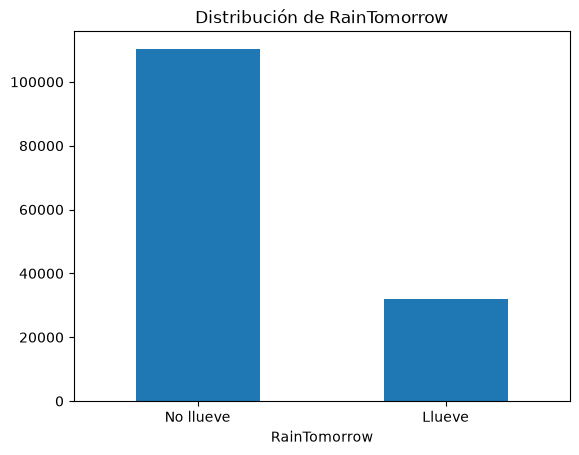

In [16]:
# cantidad y porcentaje de cada clase del target
conteo = df["RainTomorrow"].value_counts()
print(conteo)
print((df["RainTomorrow"].value_counts(normalize=True) * 100).round(2))
conteo.plot.bar()
plt.xticks([0, 1], ["No llueve", "Llueve"], rotation=0)
plt.title("Distribución de RainTomorrow")
plt.show()

El dataset **no está balanceado**: la clase "No llueve" es claramente la mayoritaria. Hacemos esta pregunta porque con clases desbalanceadas la *exactitud* engaña: un modelo que siempre responde "no llueve" tendría una exactitud alta sin haber aprendido nada. Por eso necesitamos métricas como recall, precision, F1 o AUC-PR, y por eso la separación train/val/test se hace para mantener la proporción de clases en cada conjunto. También vamos a probar `class_weight="balanced"` en la regresión logística.

### Matriz de correlación

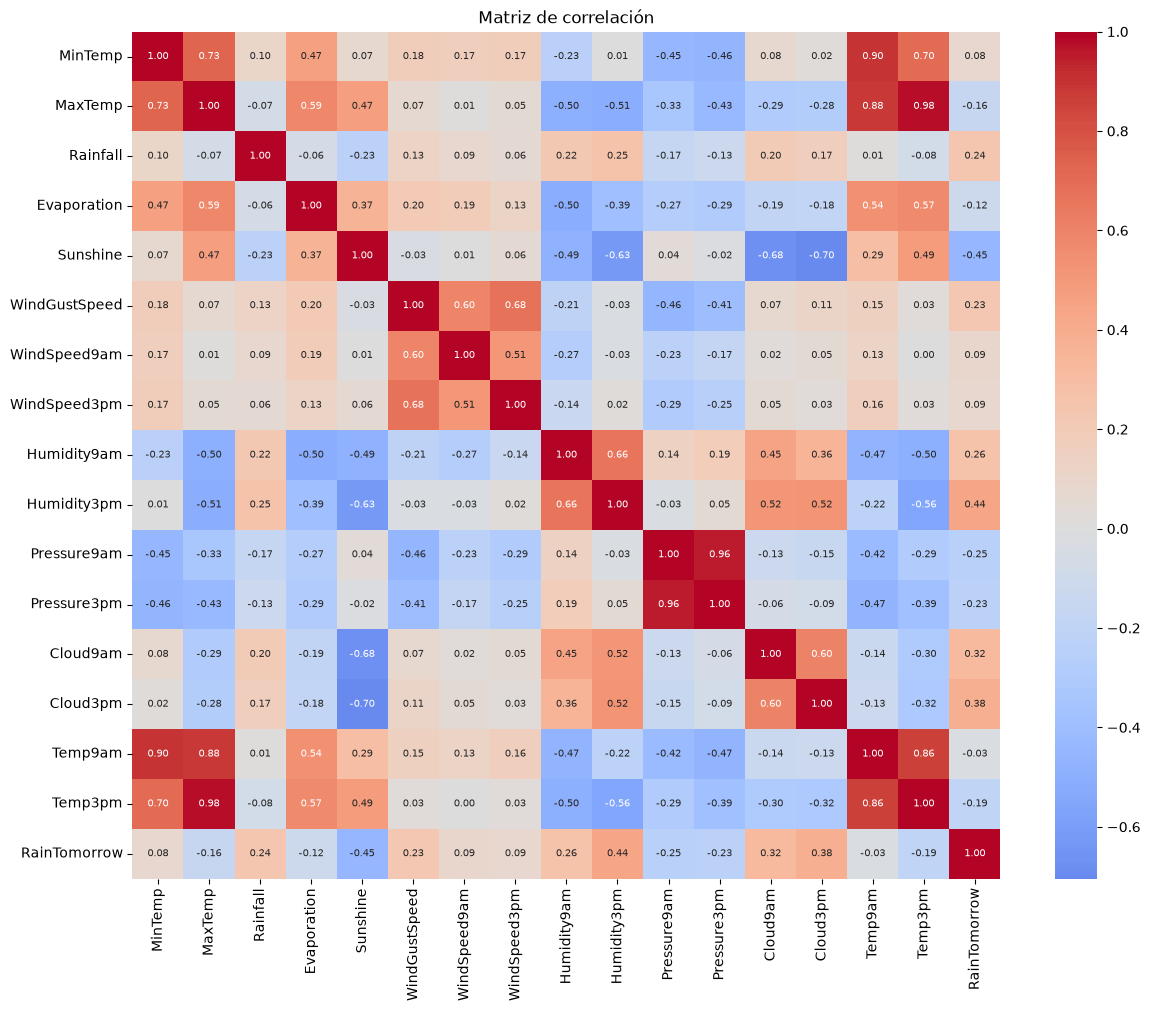

In [17]:
# matriz de correlación de las variables numéricas (incluyendo el target)
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.show()

In [18]:
# relaciones de variables con multicolinealidad
for col in corr.columns:
    for col2 in corr.columns:
        if col < col2 and abs(corr.loc[col, col2]) > 0.8:
            print(col, "-", col2, ":", round(corr.loc[col, col2], 2))

MinTemp - Temp9am : 0.9
MaxTemp - Temp9am : 0.88
MaxTemp - Temp3pm : 0.98
Pressure3pm - Pressure9am : 0.96
Temp3pm - Temp9am : 0.86


- Hay grupos de variables muy correlacionadas entre sí: las temperaturas (`MinTemp`, `MaxTemp`, `Temp9am`, `Temp3pm`) y las presiones de las 9am y 3pm. Esto es esperable porque miden casi lo mismo a distintas horas.
- Las variables más correlacionadas con el target son `Humidity3pm` (positiva) y `Sunshine` (negativa), seguidas por las nubosidades, `Humidity9am` y las presiones (negativa).
- Decidimos **no eliminar** las variables correlacionadas por ahora: la regresión logística con regularización L2 (la de por defecto) soporta bien la multicolinealidad.

### Preparación de variables

Armamos las variables que van al modelo:
- `Date` se reemplaza por el mes, codificado con seno y coseno para que diciembre y enero queden "cerca" (es una variable cíclica).
- `RainToday` se pasa a 0/1.
- Las direcciones de viento (16 puntos cardinales) también son cíclicas: se convierten a ángulo y luego a seno y coseno, en vez de generar 16 columnas dummy por cada una.
- `Location` se codifica con one-hot (no tiene orden).

In [19]:
# se crean las variables de mes (cíclicas), se pasa RainToday a 0/1 y se elimina lo que no se usa
df["Month"] = df["Date"].dt.month
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)
df["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1})

df_model = df.drop(columns=cols_a_eliminar + ["Date", "Month"])
df_model.columns.tolist()

['Location',
 'MinTemp',
 'MaxTemp',
 'Rainfall',
 'WindGustDir',
 'WindGustSpeed',
 'WindDir9am',
 'WindDir3pm',
 'WindSpeed9am',
 'WindSpeed3pm',
 'Humidity9am',
 'Humidity3pm',
 'Pressure9am',
 'Pressure3pm',
 'Cloud9am',
 'Temp9am',
 'Temp3pm',
 'RainToday',
 'RainTomorrow',
 'Month_sin',
 'Month_cos']

In [20]:
# se agrupan las columnas según el tratamiento que va a recibir cada una
cols_viento = [c for c in ["WindGustDir", "WindDir9am", "WindDir3pm"] if c in df_model.columns]
cols_ciclicas = ["Month_sin", "Month_cos"]
cols_cat = cols_viento + ["Location", "RainToday"]
cols_num = [c for c in df_model.columns
            if c not in cols_cat + cols_ciclicas + ["RainTomorrow"]]
print("Numéricas continuas:", cols_num)
print("Categóricas:", cols_cat)

Numéricas continuas: ['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Temp9am', 'Temp3pm']
Categóricas: ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'Location', 'RainToday']


### Separación en train, validación y test

Separamos antes de imputar y escalar, para que ningún estadístico se calcule con datos que el modelo no debería ver. Usamos 60% entrenamiento, 20% validación y 20% test, siempre estratificado por el target.

- **Train**: ajusta el modelo, los imputers y el scaler.
- **Validación**: se usa para comparar modelos y elegir el umbral de decisión.
- **Test**: se toca solo al final, para reportar el desempeño.

In [21]:
# se separa test (20%) y luego validación (25% de lo que queda = 20% del total), estratificando por el target
X = df_model.drop(columns="RainTomorrow")
y = df_model["RainTomorrow"]

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=SEED)

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(nombre, len(yy), "filas | % lluvia:", round(yy.mean() * 100, 2))

train 85291 filas | % lluvia: 22.42
val 28431 filas | % lluvia: 22.42
test 28431 filas | % lluvia: 22.42


### Imputación de faltantes

In [22]:
# se calculan medianas y modas SOLO con train y se utilizan para rellenar los tres conjuntos
medianas = X_train[cols_num].median()
modas = X_train[cols_cat].mode().iloc[0]

def imputar(X_):
    X_ = X_.copy()
    X_[cols_num] = X_[cols_num].fillna(medianas)
    X_[cols_cat] = X_[cols_cat].fillna(modas)
    return X_

X_train_imp = imputar(X_train)
X_val_imp = imputar(X_val)
X_test_imp = imputar(X_test)
print("Faltantes restantes en train:", X_train_imp.isna().sum().sum())

Faltantes restantes en train: 0


### Codificación de variables categóricas

In [23]:
# direcciones de viento a ángulo (16 puntos cardinales, cada 22.5 grados)
direcciones = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
angulo = {d: i * 2 * np.pi / 16 for i, d in enumerate(direcciones)}

def codificar(X_):
    X_ = X_.copy()
    # viento: seno y coseno del ángulo
    for c in cols_viento:
        ang = X_[c].map(angulo)
        X_[c + "_sin"] = np.sin(ang)
        X_[c + "_cos"] = np.cos(ang)
    X_ = X_.drop(columns=cols_viento)
    # ciudad: one-hot
    X_ = pd.get_dummies(X_, columns=["Location"], dtype=float)
    return X_

X_train_enc = codificar(X_train_imp)
columnas_finales = X_train_enc.columns
# se alinea val y test con las columnas de train (si falta alguna ciudad se completa con 0)
X_val_enc = codificar(X_val_imp).reindex(columns=columnas_finales, fill_value=0)
X_test_enc = codificar(X_test_imp).reindex(columns=columnas_finales, fill_value=0)
print("Cantidad de variables de entrada:", len(columnas_finales))

Cantidad de variables de entrada: 71


### Estandarización

Escalamos solo las variables numéricas continuas con `StandardScaler` (media 0, desvío 1), ajustado con train. Es importante para la regresión logística con regularización, porque la penalización depende de la escala de los coeficientes, y también ayuda a que el solver converja. Las dummies y las variables seno/coseno ya están en rangos chicos y no se escalan.

In [24]:
# se ajusta el scaler con train y se transforman los tres conjuntos
scaler = StandardScaler().fit(X_train_enc[cols_num])

def escalar(X_):
    X_ = X_.copy()
    X_[cols_num] = scaler.transform(X_[cols_num])
    return X_

X_train_s = escalar(X_train_enc)
X_val_s = escalar(X_val_enc)
X_test_s = escalar(X_test_enc)
X_train_s[cols_num].describe().loc[["mean", "std"]].round(2)

,MinTemp,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Temp9am,Temp3pm
mean,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 2. Regresión logística

Antes de entrenar, definimos funciones para calcular métricas y graficar, así se reutilizan con todos los modelos.

Las métricas que vamos a usar:
- **Accuracy**: proporción de aciertos. Poco confiable con clases desbalanceadas.
- **Precision**: de los días que predijimos lluvia, cuántos realmente llovieron.
- **Recall**: de los días que realmente llovieron, cuántos detectamos.
- **F1**: media armónica entre precision y recall.
- **Balanced accuracy**: promedio del recall de cada clase.
- **MCC** (Matthews): correlación entre predicción y realidad, usa los cuatro valores de la matriz de confusión y sirve con clases desbalanceadas.
- **ROC AUC** y **PR AUC** (average precision): miden la calidad del ranking de probabilidades sin depender de un umbral. La PR AUC es más exigente cuando la clase positiva es minoritaria.

In [25]:
# funciones para calcular métricas y graficar matrices de confusión
def metricas(y_true, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y_true, pred),
        "MCC": matthews_corrcoef(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, proba),
        "PR AUC": average_precision_score(y_true, proba),
    }

def graficar_cm(ax, y_true, proba, titulo, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=["No llueve", "Llueve"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(titulo)
    ax.grid(False)

In [26]:
# se entrena la regresión logística común y otra con class_weight="balanced"
logreg = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_s, y_train)
logreg_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(X_train_s, y_train)

# probabilidades de la clase "llueve" en cada conjunto
proba = {
    "LogReg": {"train": logreg.predict_proba(X_train_s)[:, 1],
               "val": logreg.predict_proba(X_val_s)[:, 1],
               "test": logreg.predict_proba(X_test_s)[:, 1]},
    "LogReg balanced": {"train": logreg_bal.predict_proba(X_train_s)[:, 1],
                        "val": logreg_bal.predict_proba(X_val_s)[:, 1],
                        "test": logreg_bal.predict_proba(X_test_s)[:, 1]},
}
y_por_set = {"train": y_train, "val": y_val, "test": y_test}

In [27]:
# métricas en train y validación (umbral 0.5) para ver si hay sobreajuste
filas = {}
for modelo in ["LogReg", "LogReg balanced"]:
    for s in ["train", "val"]:
        filas[(modelo, s)] = metricas(y_por_set[s], proba[modelo][s])
tabla_lr = pd.DataFrame(filas).T
tabla_lr.round(3)

Accuracy  Precision  Recall     F1  Balanced Acc  \
LogReg          train     0.846      0.728   0.500  0.593         0.723   
                val       0.842      0.720   0.484  0.579         0.715   
LogReg balanced train     0.788      0.519   0.766  0.619         0.780   
                val       0.785      0.515   0.763  0.615         0.777   

                         MCC  ROC AUC  PR AUC  
LogReg          train  0.516    0.863   0.695  
                val    0.501    0.859   0.683  
LogReg balanced train  0.497    0.864   0.691  
                val    0.491    0.860   0.680

Las métricas de train y validación son muy parecidas, así que no hay sobreajuste. Entre la regresión logística común y la balanceada se ve el trade-off esperable: la balanceada sube el recall (detecta más días de lluvia) a costa de bajar la precision y la accuracy. Los AUC prácticamente no cambian, porque `class_weight` no modifica el ranking de las probabilidades de forma importante, solo desplaza el punto de corte efectivo.

In [28]:
y_pred1 = (proba["LogReg"]["val"] >= 0.5).astype(int)
print(pd.crosstab(y_val, y_pred1))

y_pred2 = (proba["LogReg balanced"]["val"] >= 0.5).astype(int)
print(pd.crosstab(y_val, y_pred2))

col_0             0     1
RainTomorrow             
0             20857  1199
1              3288  3087
col_0             0     1
RainTomorrow             
0             17470  4586
1              1513  4862


**Falsos positivos y falsos negativos**

- **Falso positivo (FP)**: el modelo dice "llueve" y no llovió. La consecuencia es una falsa alarma: llevar paraguas de más, suspender una actividad que se podía hacer.
- **Falso negativo (FN)**: el modelo dice "no llueve" y llovió. Es el error más costoso en la mayoría de los casos prácticos (cosecha sin cubrir, evento al aire libre sin plan B, mojarse).

Como creemos que el FN es más costoso, nos interesa priorizar el **recall** de la clase "llueve" sin que la precision caiga demasiado, y por eso miramos el F1 y no solo la accuracy. La regresión logística común comete muchos FN, que es lo que se ve en la matriz.

### Curva ROC y umbral de decisión

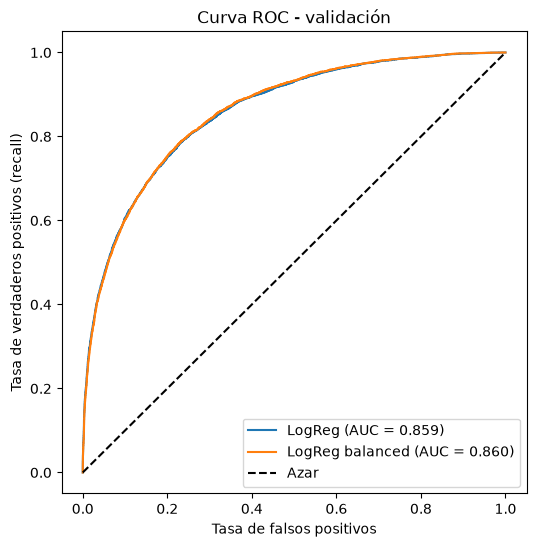

In [29]:
# curvas ROC en validación
plt.figure(figsize=(6, 6))
for modelo in ["LogReg", "LogReg balanced"]:
    fpr, tpr, _ = roc_curve(y_val, proba[modelo]["val"])
    plt.plot(fpr, tpr, label=f"{modelo} (AUC = {roc_auc_score(y_val, proba[modelo]['val']):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curva ROC - validación")
plt.legend()
plt.show()

Las dos curvas casi se superponen, como ya anticipaba el AUC. El AUC es alto, por lo que el modelo ordena bastante bien los días de lluvia respecto de los que no, pero el umbral de 0.5 no es necesariamente el que mejor aprovecha ese ranking.

**¿Es 0.5 el mejor umbral?** No tiene por qué. El 0.5 es solo el valor por defecto y funciona bien cuando las clases están balanceadas y los errores cuestan lo mismo. Acá no pasa ninguna de las dos cosas. Dos formas de elegir el umbral:
1. **Índice de Youden**: el punto de la ROC que maximiza `TPR - FPR`.
2. **Maximizar el F1** sobre la curva precision-recall.

Los umbrales se eligen con el conjunto de **validación** (nunca con test, para no sesgar la evaluación final).

In [30]:
# se busca el umbral óptimo en validación con Youden y con F1 máximo
def mejores_umbrales(y_true, p):
    fpr, tpr, thr = roc_curve(y_true, p)
    umbral_youden = thr[np.argmax(tpr - fpr)]
    prec, rec, thr_pr = precision_recall_curve(y_true, p)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    umbral_f1 = thr_pr[np.argmax(f1s)]
    return umbral_youden, umbral_f1

umbrales = {}
for modelo in ["LogReg", "LogReg balanced"]:
    umbrales[modelo] = mejores_umbrales(y_val, proba[modelo]["val"])
    print(f"{modelo}: umbral Youden = {umbrales[modelo][0]:.3f} | umbral F1 máx = {umbrales[modelo][1]:.3f}")

LogReg: umbral Youden = 0.204 | umbral F1 máx = 0.317
LogReg balanced: umbral Youden = 0.469 | umbral F1 máx = 0.619


In [31]:
# se compara en validación el umbral 0.5 con los umbrales óptimos (regresión logística común)
p_val = proba["LogReg"]["val"]
comp = pd.DataFrame({
    "0.5": metricas(y_val, p_val, 0.5),
    "Youden": metricas(y_val, p_val, umbrales["LogReg"][0]),
    "F1 máx": metricas(y_val, p_val, umbrales["LogReg"][1]),
}).T
comp.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
0.5,0.842,0.720,0.484,0.579,0.715,0.501,0.859,0.683
Youden,0.772,0.495,0.786,0.607,0.777,0.482,0.859,0.683
F1 máx,0.822,0.592,0.658,0.623,0.764,0.508,0.859,0.683


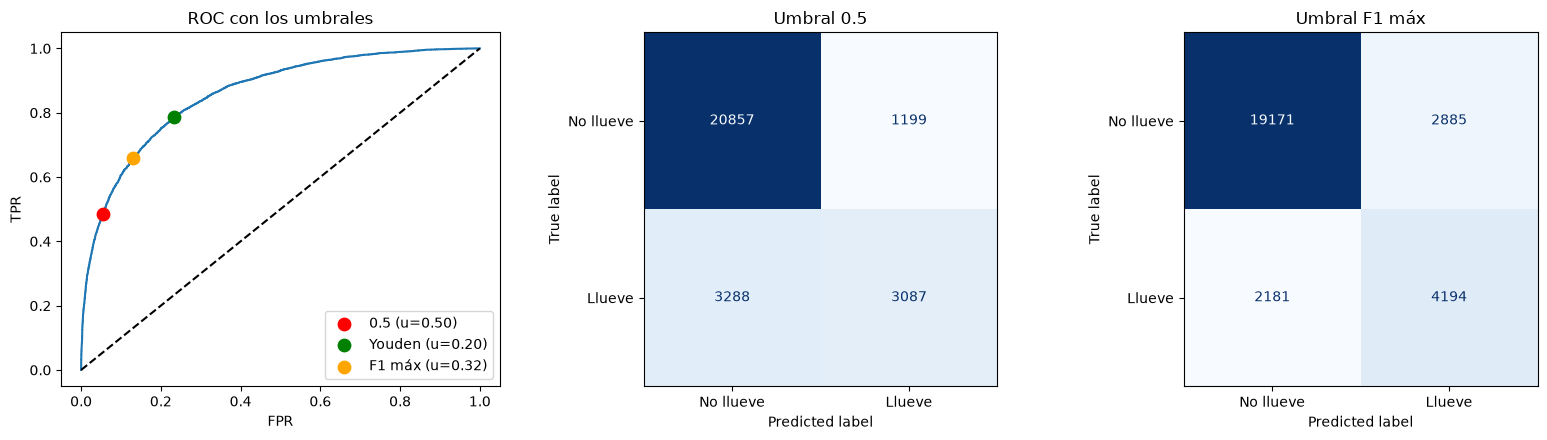

In [32]:
# punto de cada umbral sobre la curva ROC y matrices de confusión con cada umbral
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y_val, p_val)
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], "k--")
for nombre, u, c in [("0.5", 0.5, "red"), ("Youden", umbrales["LogReg"][0], "green"), ("F1 máx", umbrales["LogReg"][1], "orange")]:
    pred = (p_val >= u).astype(int)
    f = ((pred == 1) & (y_val == 0)).sum() / (y_val == 0).sum()
    t = ((pred == 1) & (y_val == 1)).sum() / (y_val == 1).sum()
    axes[0].scatter(f, t, color=c, s=80, zorder=3, label=f"{nombre} (u={u:.2f})")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].set_title("ROC con los umbrales")
axes[0].legend()
graficar_cm(axes[1], y_val, p_val, "Umbral 0.5")
graficar_cm(axes[2], y_val, p_val, "Umbral F1 máx", umbral=umbrales["LogReg"][1])
plt.tight_layout()
plt.show()

Con un umbral más bajo que 0.5 el modelo detecta más días de lluvia (sube el recall y el F1) a cambio de más falsas alarmas. Para el problema, donde un falso negativo suele ser peor que una falsa alarma, ese cambio tiene sentido. El umbral de Youden da el mismo peso a FP y FN en términos de tasas, mientras que el de F1 se enfoca en la clase positiva. Si se conociera el costo real de cada error, el umbral se podría elegir minimizando el costo esperado.

Para el resto del trabajo usamos el **umbral que maximiza el F1 en validación**.

In [33]:
# resultado final de la regresión logística en test, con el umbral 0.5 y con el umbral elegido
UMBRAL_LR = umbrales["LogReg"][1]
p_test = proba["LogReg"]["test"]
res_test_lr = pd.DataFrame({
    "LogReg (u=0.5)": metricas(y_test, p_test, 0.5),
    "LogReg (u=F1 máx)": metricas(y_test, p_test, UMBRAL_LR),
}).T
res_test_lr.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
LogReg (u=0.5),0.846,0.730,0.497,0.591,0.722,0.515,0.864,0.698
LogReg (u=F1 máx),0.825,0.598,0.666,0.630,0.768,0.517,0.864,0.698


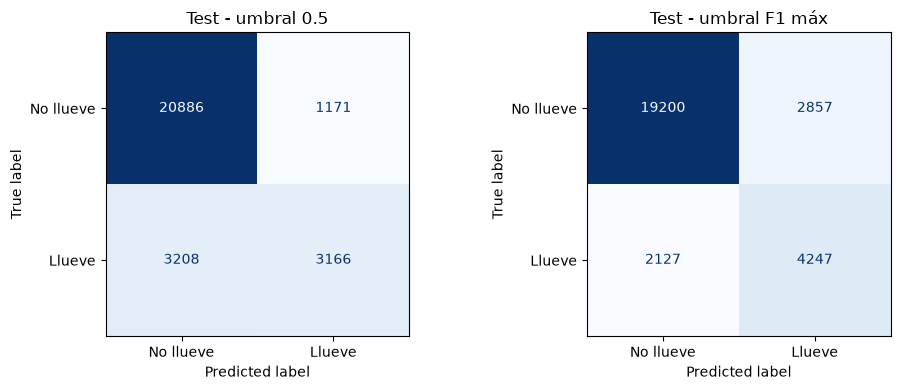

In [34]:
# matrices de confusión en test con ambos umbrales
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
graficar_cm(axes[0], y_test, p_test, "Test - umbral 0.5")
graficar_cm(axes[1], y_test, p_test, "Test - umbral F1 máx", umbral=UMBRAL_LR)
plt.tight_layout()
plt.show()

### ¿Conseguimos un buen fitting?

- **Sobreajuste**: no. Las métricas de train y validación son casi iguales, y test se comporta igual que validación.
- **Subajuste**: es posible que haya algo. La regresión logística es un modelo lineal, y el problema probablemente tenga interacciones y no linealidades que no captura (por ejemplo, el efecto combinado de humedad y presión). Además, con el umbral 0.5 el recall de la clase "llueve" es bajo.
- Aun así, es un buen punto de partida: el AUC es alto, el ajuste es estable y, con el umbral bien elegido, el balance entre precision y recall mejora bastante. Modelos más flexibles (los que vienen en los ítems siguientes) podrían mejorarlo.

## 3. Modelo base

Un modelo base sirve de piso: cualquier modelo más complejo tiene que superarlo para justificarse. Usamos tres:

1. **Dummy "siempre No"** (`most_frequent`): predice siempre la clase mayoritaria. Muestra lo que daría la accuracy sin aprender nada.
2. **Dummy estratificado**: predice al azar respetando la proporción de clases de train.
3. **Regla simple "mañana llueve si hoy llovió"**: usa solo `RainToday`. Es un baseline con sentido meteorológico y no usa ningún aprendizaje.

In [35]:
# se entrenan los dos modelos dummy y se arman las probabilidades de los tres baselines
dummy_mf = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
dummy_est = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train_s, y_train)

def probas_base(X_s):
    return {
        "Base: siempre No": dummy_mf.predict_proba(X_s)[:, 1],
        "Base: azar estratificado": dummy_est.predict_proba(X_s)[:, 1],
        "Base: RainToday": X_s["RainToday"].values.astype(float),
    }

proba_base = {"train": probas_base(X_train_s), "val": probas_base(X_val_s), "test": probas_base(X_test_s)}

In [36]:
# métricas de los baselines en validación (umbral 0.5)
tabla_base = pd.DataFrame({m: metricas(y_val, p) for m, p in proba_base["val"].items()}).T
tabla_base.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
Base: siempre No,0.776,0.000,0.000,0.000,0.500,0.000,0.500,0.224
Base: azar estratificado,0.653,0.225,0.224,0.225,0.501,0.001,0.501,0.224
Base: RainToday,0.760,0.464,0.461,0.462,0.653,0.308,0.653,0.335


El "siempre No" tiene una accuracy parecida a la proporción de la clase mayoritaria pero recall 0 y F1 0: nunca detecta una lluvia. Esto confirma por qué la accuracy sola no sirve en este problema. El dummy estratificado queda en AUC de 0.5 (azar). La regla `RainToday` es el baseline más interesante: da un recall y un F1 que no son despreciables usando una sola variable, y es el valor a superar.

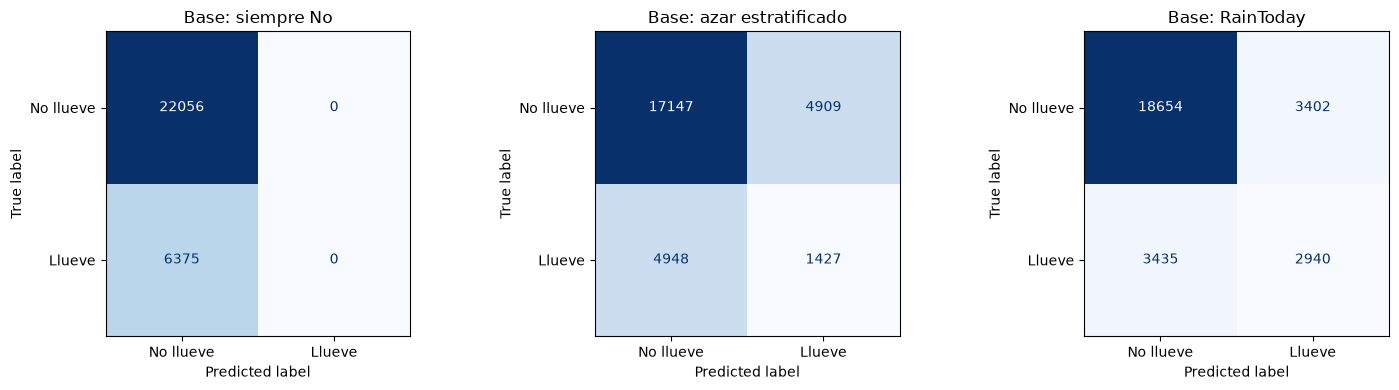

In [37]:
# matrices de confusión de los baselines en validación
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (m, p) in zip(axes, proba_base["val"].items()):
    graficar_cm(ax, y_val, p, m)
plt.tight_layout()
plt.show()

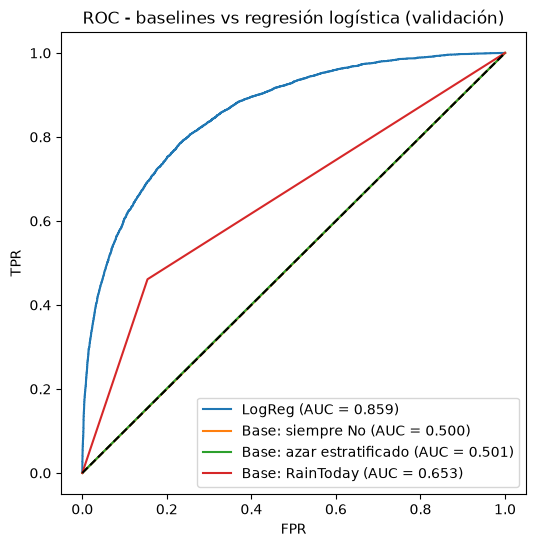

In [38]:
# curvas ROC de baselines y regresión logística en validación
plt.figure(figsize=(6, 6))
plt.plot(*roc_curve(y_val, proba["LogReg"]["val"])[:2], label=f"LogReg (AUC = {roc_auc_score(y_val, proba['LogReg']['val']):.3f})")
for m, p in proba_base["val"].items():
    plt.plot(*roc_curve(y_val, p)[:2], label=f"{m} (AUC = {roc_auc_score(y_val, p):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC - baselines vs regresión logística (validación)")
plt.legend()
plt.show()

Las curvas de los baselines con probabilidades constantes o binarias son rectas o puntos sobre la diagonal (o cerca), porque no hay un ranking real de probabilidades que recorrer. Por eso en los baselines no tiene sentido buscar un umbral: la regresión logística es la única con una curva ROC realmente por encima del azar.

### Comparación en test: baselines vs regresión logística

In [39]:
# tabla final de este entregable, evaluada en test
resultados_test = {
    "LogReg (u=0.5)": metricas(y_test, proba["LogReg"]["test"], 0.5),
    "LogReg (u=F1 máx)": metricas(y_test, proba["LogReg"]["test"], UMBRAL_LR),
    "LogReg balanced (u=0.5)": metricas(y_test, proba["LogReg balanced"]["test"], 0.5),
}
for m, p in proba_base["test"].items():
    resultados_test[m] = metricas(y_test, p)

tabla_final = pd.DataFrame(resultados_test).T.sort_values("F1", ascending=False)
tabla_final.round(3)

,Accuracy,Precision,Recall,F1,Balanced Acc,MCC,ROC AUC,PR AUC
LogReg (u=F1 máx),0.825,0.598,0.666,0.630,0.768,0.517,0.864,0.698
LogReg balanced (u=0.5),0.789,0.520,0.762,0.618,0.779,0.496,0.864,0.695
LogReg (u=0.5),0.846,0.730,0.497,0.591,0.722,0.515,0.864,0.698
Base: RainToday,0.757,0.458,0.455,0.456,0.649,0.300,0.649,0.330
Base: azar estratificado,0.656,0.230,0.229,0.229,0.504,0.008,0.504,0.226
Base: siempre No,0.776,0.000,0.000,0.000,0.500,0.000,0.500,0.224


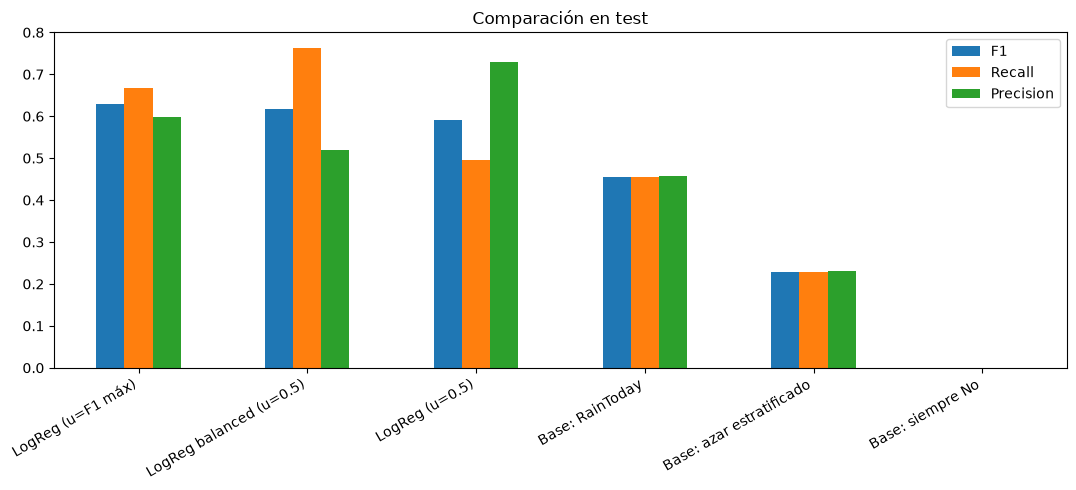

In [40]:
# gráfico de barras con F1 y recall de cada modelo en test
tabla_final[["F1", "Recall", "Precision"]].plot.bar(figsize=(11, 5))
plt.xticks(rotation=30, ha="right")
plt.title("Comparación en test")
plt.tight_layout()
plt.show()

**Conclusiones de la primera etapa**

- El dataset está desbalanceado, por lo que la accuracy no alcanza para evaluar: usamos F1, recall, MCC y AUC.
- La regresión logística supera claramente a todos los baselines en F1, MCC y AUC. Es decir, aprende algo más que "si hoy llovió, mañana llueve".
- El umbral 0.5 no es el mejor para este problema. Bajarlo (usando el F1 máximo en validación) mejora el balance entre precision y recall.
- El fitting es estable (train, validación y test parecidos), pero al ser un modelo lineal puede estar limitado. En las próximas entregas vamos a optimizar hiperparámetros, explicar el modelo y probar modelos más flexibles (AutoML y redes neuronales).

## 4. Selección de hiperparametros optimizada

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

param_grid = {
   "C": [0.01, 0.1, 1, 10, 100],
   "solver": ["lbfgs"],
   "class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator = proba["LogReg"],
    param_grid = param_grid,
    scoring = "f1",
    cv = kfold,
    n_jobs = -1
)

InvalidParameterError: The 'estimator' parameter of GridSearchCV must be an object implementing 'fit'. Got {'train': array([0.147611  , 0.34187049, 0.00472881, ..., 0.19961804, 0.05974612,
       0.45056664], shape=(85291,)), 'val': array([0.11252931, 0.07033357, 0.10506172, ..., 0.63492956, 0.2223533 ,
       0.03163651], shape=(28431,)), 'test': array([0.0365225 , 0.10240029, 0.05881378, ..., 0.0365817 , 0.16883352,
       0.03959247], shape=(28431,))} instead.